# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**: Dataset yang digunakan adalah **German Credit Data (Credit Scoring)** dari UCI Machine Learning Repository (Statlog German Credit Data), versi dengan nilai kategori yang mudah dibaca.

2. **Deskripsi**: Dataset berisi **1.000 data** pemohon kredit dengan **20 fitur** (7 numerik, 13 kategorikal) dan **1 target** `default`:
   - `1` = nasabah baik (*good credit*)
   - `2` = nasabah gagal bayar (*bad credit / default*)

3. **Tujuan**: Membangun model klasifikasi untuk memprediksi apakah seorang pemohon berisiko gagal bayar (*credit scoring*).

| Fitur | Keterangan |
|---|---|
| checking_balance | Saldo rekening giro |
| months_loan_duration | Lama pinjaman (bulan) |
| credit_history | Riwayat kredit |
| purpose | Tujuan pinjaman |
| amount | Jumlah pinjaman (DM) |
| savings_balance | Saldo tabungan |
| employment_length | Lama bekerja |
| installment_rate | Persentase cicilan terhadap pendapatan |
| personal_status | Status personal & jenis kelamin |
| other_debtors | Penjamin / debitur lain |
| residence_history | Lama tinggal di alamat sekarang |
| property | Kepemilikan properti |
| age | Usia |
| installment_plan | Rencana cicilan lain |
| housing | Status tempat tinggal |
| existing_credits | Jumlah kredit berjalan |
| dependents | Jumlah tanggungan |
| telephone | Memiliki telepon |
| foreign_worker | Pekerja asing |
| job | Jenis pekerjaan |
| **default** | **Target** |


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Dataset mentah tersimpan di folder `credit_raw`.

In [2]:
RAW_PATH = "../credit_raw/credit_raw.csv"
df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1000, 21)


,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,residence_history,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job
0,< 0 DM,6,critical,radio/tv,1169,unknown,> 7 yrs,4,single male,none,4,real estate,67,none,own,2,1,1,yes,yes,skilled employee
1,1 - 200 DM,48,repaid,radio/tv,5951,< 100 DM,1 - 4 yrs,2,female,none,2,real estate,22,none,own,1,2,1,none,yes,skilled employee
2,unknown,12,critical,education,2096,< 100 DM,4 - 7 yrs,2,single male,none,3,real estate,49,none,own,1,1,2,none,yes,unskilled resident
3,< 0 DM,42,repaid,furniture,7882,< 100 DM,4 - 7 yrs,2,single male,guarantor,4,building society savings,45,none,for free,1,1,2,none,yes,skilled employee
4,< 0 DM,24,delayed,car (new),4870,< 100 DM,1 - 4 yrs,3,single male,none,4,unknown/none,53,none,for free,2,2,2,none,yes,skilled employee


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   checking_balance      1000 non-null   object
 1   months_loan_duration  1000 non-null   int64 
 2   credit_history        1000 non-null   object
 3   purpose               1000 non-null   object
 4   amount                1000 non-null   int64 
 5   savings_balance       1000 non-null   object
 6   employment_length     1000 non-null   object
 7   installment_rate      1000 non-null   int64 
 8   personal_status       1000 non-null   object
 9   other_debtors         1000 non-null   object
 10  residence_history     1000 non-null   int64 
 11  property              1000 non-null   object
 12  age                   1000 non-null   int64 
 13  installment_plan      1000 non-null   object
 14  housing               1000 non-null   object
 15  existing_credits      1000 non-null   i

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

### 4.1 Statistik deskriptif

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
months_loan_duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_history,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
default,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0
dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


In [5]:
df.describe(include="object").T

,count,unique,top,freq
checking_balance,1000,4,unknown,394
credit_history,1000,5,repaid,530
purpose,1000,10,radio/tv,280
savings_balance,1000,5,< 100 DM,603
employment_length,1000,5,1 - 4 yrs,339
personal_status,1000,4,single male,548
other_debtors,1000,3,none,907
property,1000,4,other,332
installment_plan,1000,3,none,814
housing,1000,3,own,713


### 4.2 Missing value & data duplikat

In [6]:
print("Jumlah missing value per kolom:")
print(df.isna().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Jumlah missing value per kolom:
checking_balance        0
months_loan_duration    0
credit_history          0
purpose                 0
amount                  0
savings_balance         0
employment_length       0
installment_rate        0
personal_status         0
other_debtors           0
residence_history       0
property                0
age                     0
installment_plan        0
housing                 0
existing_credits        0
default                 0
dependents              0
telephone               0
foreign_worker          0
job                     0
dtype: int64

Jumlah data duplikat: 0


### 4.3 Distribusi target

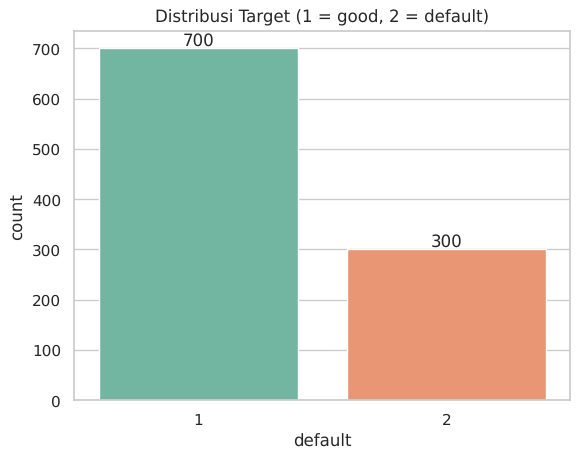

default
1    0.7
2    0.3
Name: proportion, dtype: float64


In [7]:
ax = sns.countplot(x="default", data=df, palette="Set2")
ax.set_title("Distribusi Target (1 = good, 2 = default)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()
print(df["default"].value_counts(normalize=True))

Dataset **tidak seimbang** (70% good, 30% default), sehingga split data dilakukan secara *stratified* dan evaluasi model sebaiknya tidak hanya menggunakan accuracy.

### 4.4 Distribusi fitur numerik

Numerik   : ['months_loan_duration', 'amount', 'installment_rate', 'residence_history', 'age', 'existing_credits', 'dependents']
Kategorikal: ['checking_balance', 'credit_history', 'purpose', 'savings_balance', 'employment_length', 'personal_status', 'other_debtors', 'property', 'installment_plan', 'housing', 'telephone', 'foreign_worker', 'job']


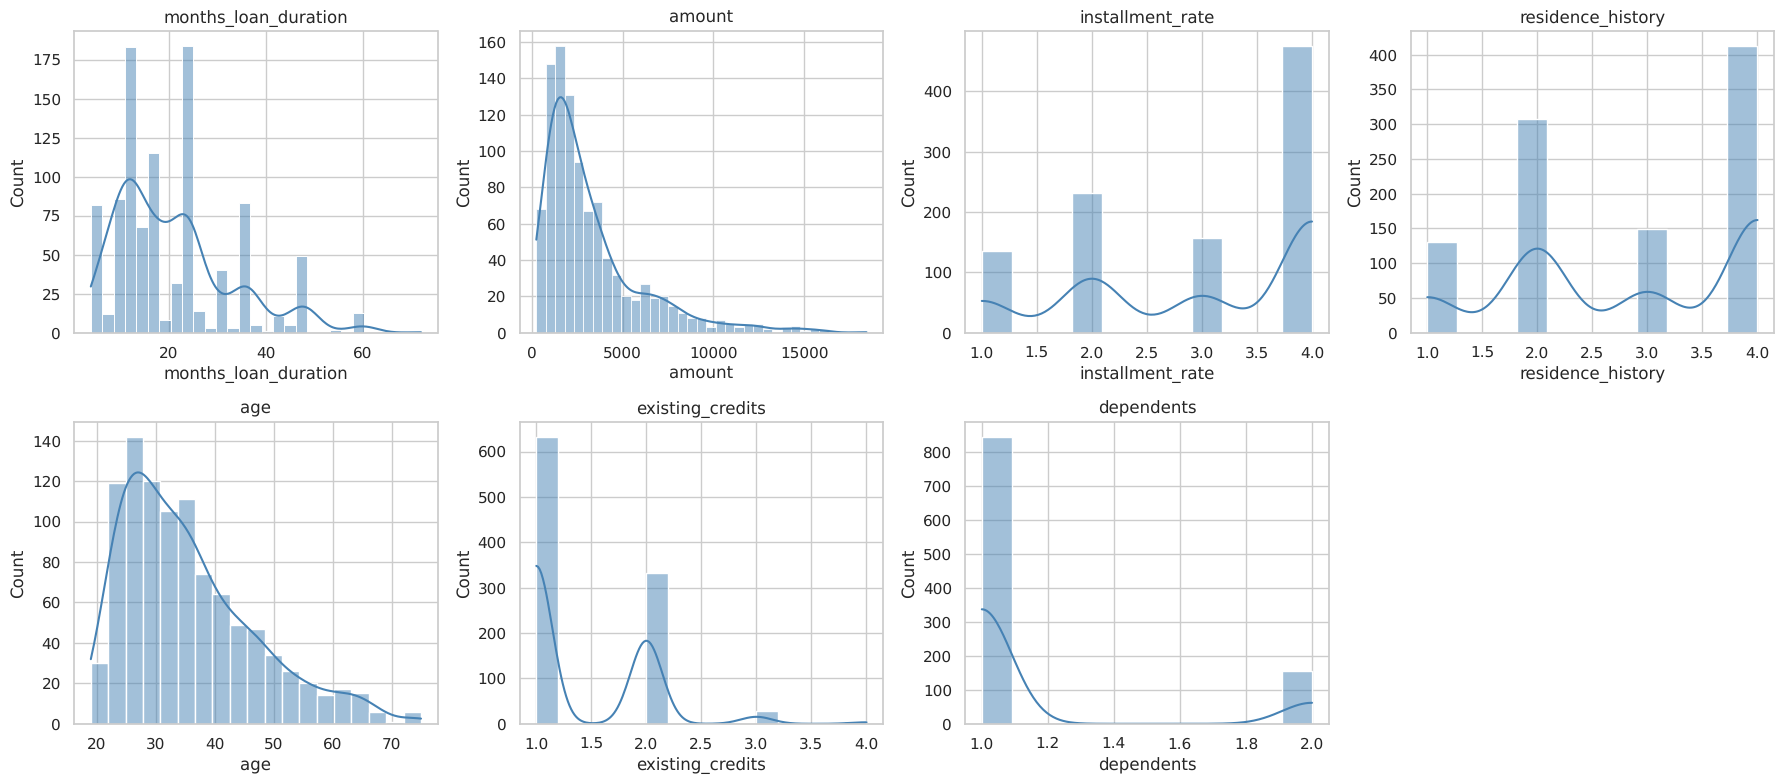

In [8]:
num_cols = df.select_dtypes(include="number").columns.drop("default").tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Numerik   :", num_cols)
print("Kategorikal:", cat_cols)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### 4.5 Deteksi outlier (boxplot)

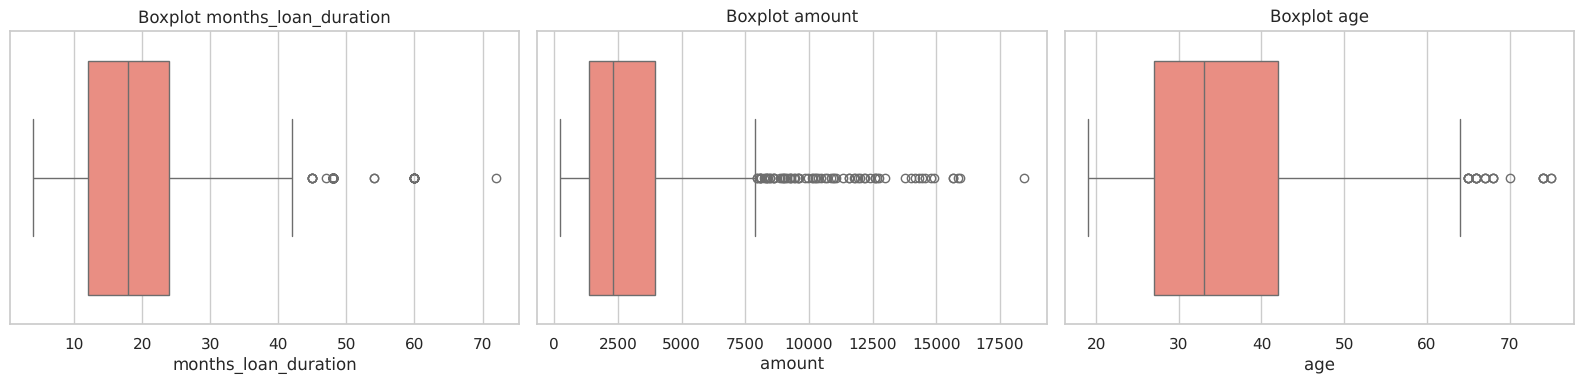

months_loan_duration  : 70 outlier
amount                : 72 outlier
age                   : 23 outlier


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["months_loan_duration", "amount", "age"]):
    sns.boxplot(x=df[col], ax=ax, color="salmon")
    ax.set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

for col in ["months_loan_duration", "amount", "age"]:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:22s}: {n_out} outlier")

### 4.6 Fitur kategorikal terhadap target

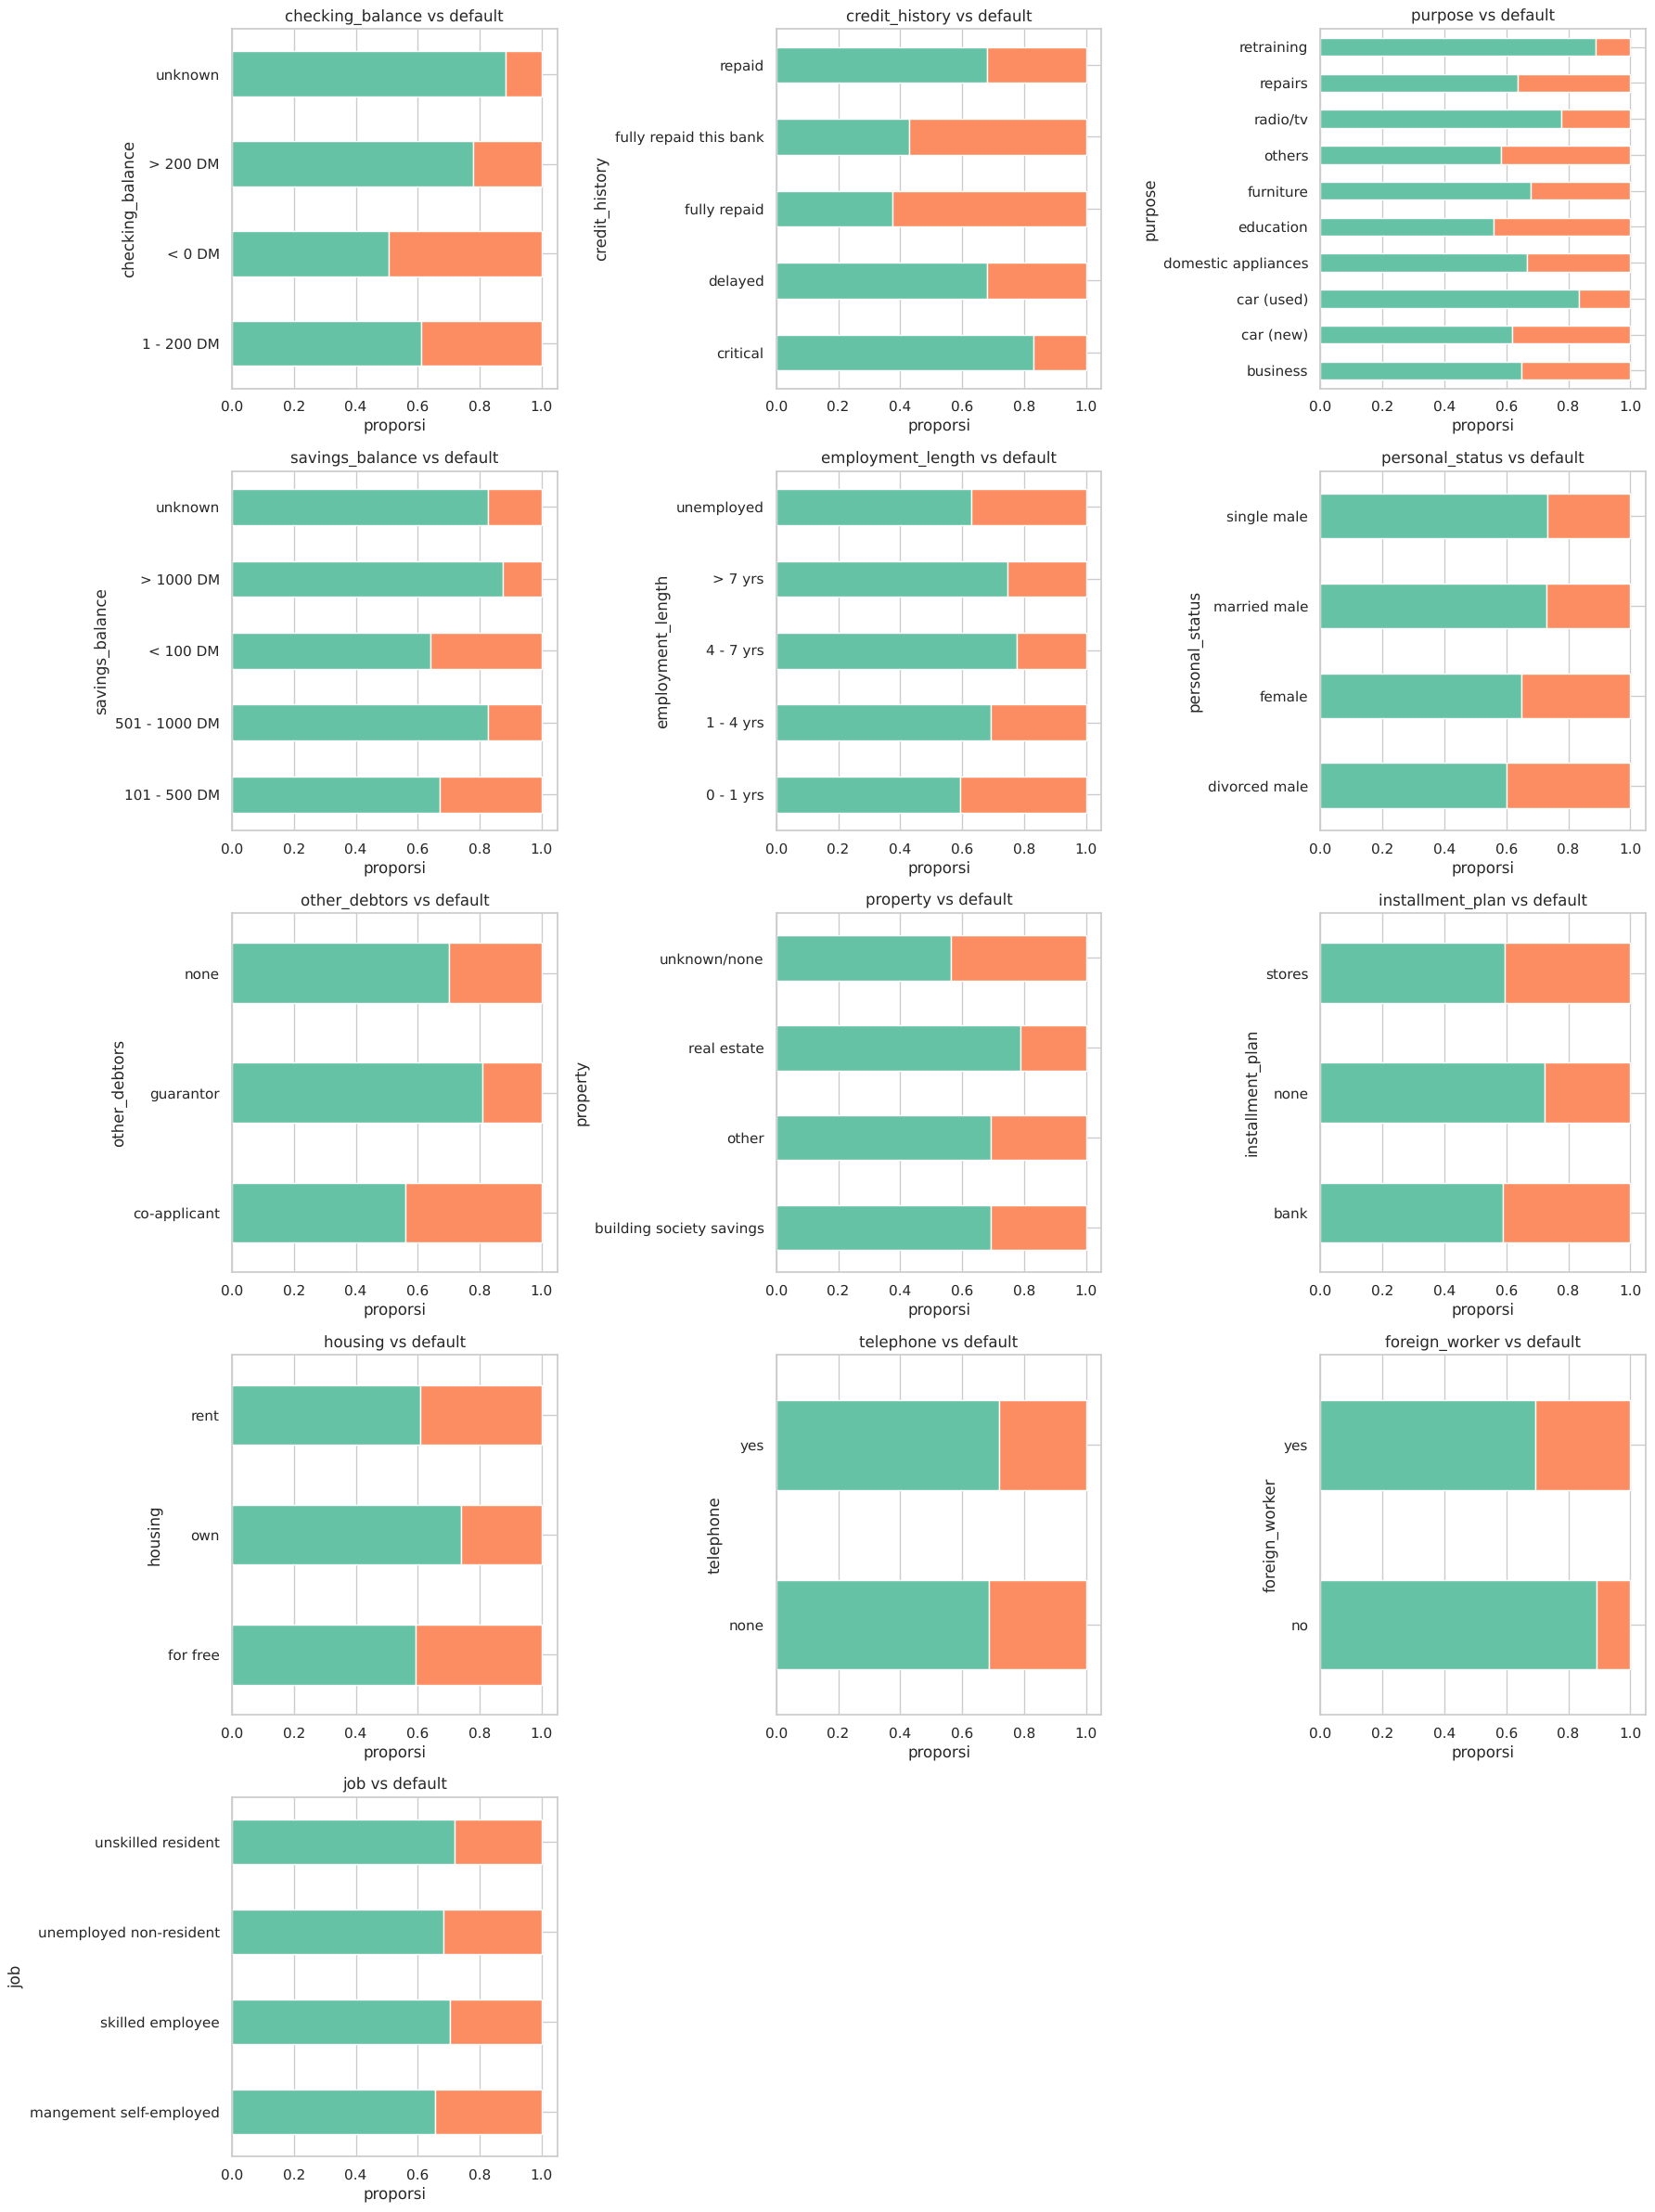

In [10]:
fig, axes = plt.subplots(5, 3, figsize=(18, 24))
for ax, col in zip(axes.flat, cat_cols):
    ct = pd.crosstab(df[col], df["default"], normalize="index")
    ct.plot(kind="barh", stacked=True, ax=ax, color=["#66c2a5", "#fc8d62"], legend=False)
    ax.set_title(f"{col} vs default")
    ax.set_xlabel("proporsi")
for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 4.7 Korelasi fitur numerik

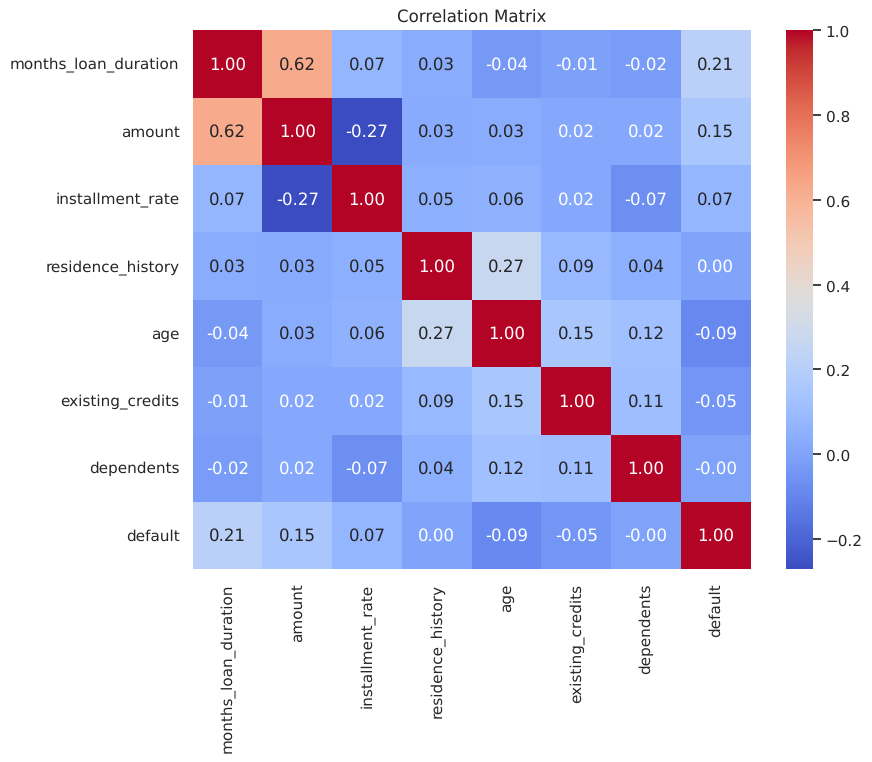

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ["default"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

**Insight EDA:**
- Tidak ada missing value maupun data duplikat.
- Target tidak seimbang (700 good : 300 default).
- `amount`, `months_loan_duration`, dan `age` memiliki distribusi *right-skewed* dengan beberapa outlier.
- Nasabah dengan `checking_balance` "< 0 DM" dan `credit_history` "critical"/"poor" cenderung memiliki proporsi default yang berbeda signifikan.
- `months_loan_duration` dan `amount` memiliki korelasi positif cukup kuat (~0.62) dan keduanya berkorelasi positif dengan target.

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Tahapan yang dilakukan:
1. Menghapus data duplikat & menangani missing value
2. Encoding target
3. Menangani outlier (IQR capping)
4. Split data train/test (stratified)
5. Standarisasi fitur numerik & One-Hot Encoding fitur kategorikal
6. Menyimpan dataset hasil preprocessing

### 5.1 Menghapus duplikat & menangani missing value

In [12]:
df_clean = df.drop_duplicates().copy()
for col in df_clean.columns:
    if df_clean[col].isna().any():
        if df_clean[col].dtype == "object":
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print("Shape setelah cleaning:", df_clean.shape)

Shape setelah cleaning: (1000, 21)


### 5.2 Encoding target
`1` (good) → `0`, `2` (default) → `1`

In [13]:
df_clean["default"] = df_clean["default"].map({1: 0, 2: 1}).astype(int)
df_clean["default"].value_counts()

default
0    700
1    300
Name: count, dtype: int64

### 5.3 Menangani outlier (IQR capping)

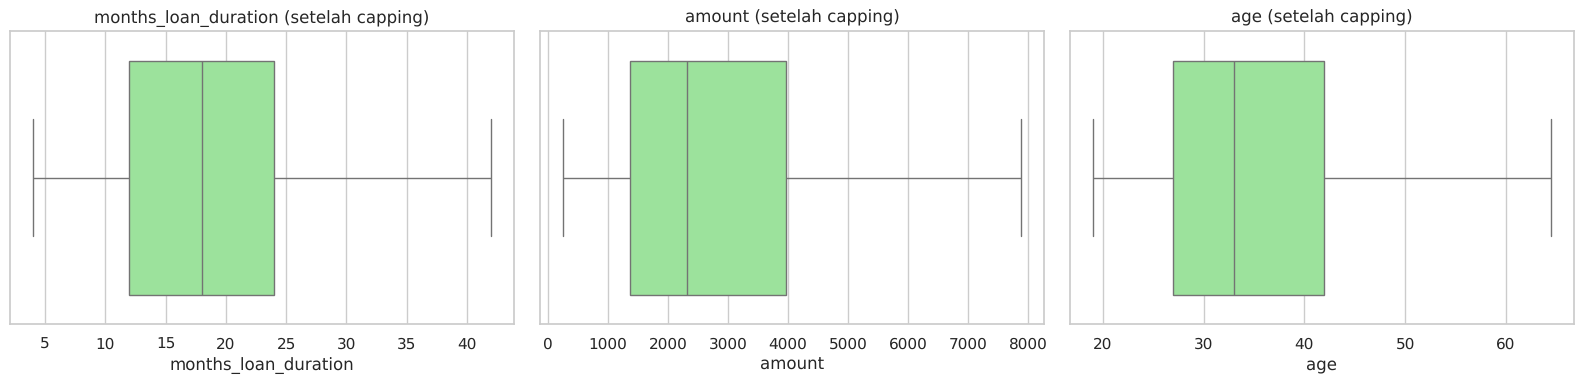

In [14]:
OUTLIER_FEATURES = ["months_loan_duration", "amount", "age"]
for col in OUTLIER_FEATURES:
    q1, q3 = df_clean[col].quantile([0.25, 0.75]); iqr = q3 - q1
    df_clean[col] = df_clean[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, OUTLIER_FEATURES):
    sns.boxplot(x=df_clean[col], ax=ax, color="lightgreen")
    ax.set_title(f"{col} (setelah capping)")
plt.tight_layout()
plt.show()

### 5.4 Split data train/test

In [15]:
TARGET = "default"
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (800, 20) | Test: (200, 20)


### 5.5 Standarisasi & One-Hot Encoding
Preprocessor hanya di-*fit* pada data train untuk mencegah *data leakage*.

In [16]:
NUMERIC_FEATURES = ["months_loan_duration", "amount", "installment_rate",
                    "residence_history", "age", "existing_credits", "dependents"]
CATEGORICAL_FEATURES = [c for c in X_train.columns if c not in NUMERIC_FEATURES]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ],
    verbose_feature_names_out=False,
)
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

train_df = pd.DataFrame(X_train_t, columns=feature_names)
train_df[TARGET] = y_train.to_numpy()
test_df = pd.DataFrame(X_test_t, columns=feature_names)
test_df[TARGET] = y_test.to_numpy()
print("Jumlah fitur setelah encoding:", len(feature_names))
train_df.head()

Jumlah fitur setelah encoding: 61


,months_loan_duration,amount,installment_rate,residence_history,age,existing_credits,dependents,checking_balance_1 - 200 DM,checking_balance_< 0 DM,checking_balance_> 200 DM,checking_balance_unknown,credit_history_critical,credit_history_delayed,credit_history_fully repaid,credit_history_fully repaid this bank,credit_history_repaid,purpose_business,purpose_car (new),purpose_car (used),purpose_domestic appliances,purpose_education,purpose_furniture,purpose_others,purpose_radio/tv,purpose_repairs,...,personal_status_female,personal_status_married male,personal_status_single male,other_debtors_co-applicant,other_debtors_guarantor,other_debtors_none,property_building society savings,property_other,property_real estate,property_unknown/none,installment_plan_bank,installment_plan_none,installment_plan_stores,housing_for free,housing_own,housing_rent,telephone_none,telephone_yes,foreign_worker_no,foreign_worker_yes,job_mangement self-employed,job_skilled employee,job_unemployed non-resident,job_unskilled resident,default
0,1.494889,2.241785,0.052281,1.053413,1.088219,-0.718745,-0.436436,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
1,-0.782495,-1.019124,0.942164,1.053413,0.255044,-0.718745,-0.436436,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0
2,1.494889,1.084829,0.052281,-0.747293,-0.670706,1.045047,-0.436436,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0
3,1.494889,0.448622,0.052281,-0.747293,-0.578131,-0.718745,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0
4,2.064234,2.241785,-1.727486,-0.747293,-1.041006,-0.718745,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0


### 5.6 Menyimpan dataset hasil preprocessing

In [17]:
OUTPUT_DIR = "credit_preprocessing"
os.makedirs(OUTPUT_DIR, exist_ok=True)
train_df.to_csv(os.path.join(OUTPUT_DIR, "train.csv"), index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR, "test.csv"), index=False)
print(os.listdir(OUTPUT_DIR))

['train.csv', 'test.csv']


Dataset hasil preprocessing (`train.csv` & `test.csv`) siap digunakan untuk pelatihan model. Tahapan di atas kemudian dikonversi menjadi file `automate_Dwi-Cahyo.py` agar preprocessing dapat dijalankan secara otomatis.